# Vehicle routing

A delivery company has a depot, a small fleet and a list of customers to serve today.
Every customer needs some capacity on the truck, a few minutes of service, and a time
window. The question is **which truck visits which customer, and in what order**.

In this notebook you will:

1. describe a delivery day as Python objects,
2. solve it and draw the routes on a map and on a timeline,
3. check the result yourself, without trusting the solver's score,
4. change the rules with constraint plugins, without touching the solver,
5. shrink the fleet and see what the solver gives up,
6. restart the search from an existing plan.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from optimaru import vehicle_routing as vrp
from optimaru.vehicle_routing import constraints as rules
from optimaru.vehicle_routing.models import (
    RoutePlanRequest, RoutingInput, VehicleModel, VisitModel, solve_request, with_initial_solution,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the delivery day

Three kinds of objects make up a plan. All times are **integer seconds from the start of
the day**, so `8 * 3600` is 08:00.

| Object | What it holds |
| --- | --- |
| `Location` | latitude and longitude. The plan sets `index`, its row in the driving-time matrix |
| `Visit` | one customer stop: location, demand, time window, service duration |
| `Vehicle` | one truck: capacity, home location, departure time, optional route limits |

Here is a fictional day: 50 customers around a depot in central Seoul, each booked into one of
four two-hour delivery slots.

In [2]:
HOUR = 3600
rng = np.random.default_rng(7)

DEPOT = (37.5665, 126.9780)
locations = [vrp.Location(*DEPOT)]  # index 0 is the depot
visits = []
SLOTS = [(9, 11), (11, 13), (13, 15), (15, 17)]
for i in range(50):
    lat = DEPOT[0] + rng.normal(0, 0.055)
    lon = DEPOT[1] + rng.normal(0, 0.075)
    locations.append(vrp.Location(lat, lon))
    opens, closes = SLOTS[i % len(SLOTS)]
    visits.append(vrp.Visit(
        id=f"C{i:02d}",
        name=f"Customer {i}",
        location_index=i + 1,
        demand=int(rng.integers(1, 6)),
        min_start_time=opens * HOUR,
        max_end_time=closes * HOUR,
        service_duration=10 * 60,
    ))


def make_plan(vehicle_count=5):
    """A fresh, unsolved plan. Solvers work in place, so each experiment gets its own."""
    vehicles = [
        vrp.Vehicle(f"Truck {k + 1}", capacity=40, home_location_index=0,
                    departure_time=8 * HOUR, return_to_depot=True)
        for k in range(vehicle_count)
    ]
    return vrp.VehicleRoutePlan("seoul-delivery", locations, vehicles, visits)


plan = make_plan()
print(f"{len(plan.visits)} visits, {len(plan.vehicles)} vehicles")
print(f"total demand {sum(v.demand for v in plan.visits)}, "
      f"fleet capacity {sum(v.capacity for v in plan.vehicles)}")

50 visits, 5 vehicles
total demand 176, fleet capacity 200


`VehicleRoutePlan` needs a driving time between every pair of locations. Pass your own
`driving_seconds` matrix from a road network if you have one. Without it the plan computes a
great-circle estimate, which is what this notebook uses.

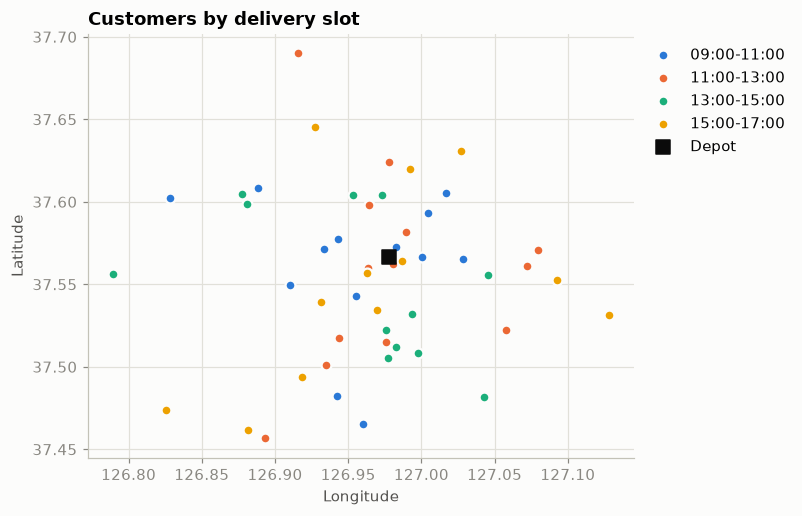

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 5))
for k, (opens, closes) in enumerate(SLOTS):
    points = [locations[v.location_index] for v in plan.visits if v.min_start_time == opens * HOUR]
    ax.scatter([p.longitude for p in points], [p.latitude for p in points], s=42, color=COLORS[k],
               edgecolor="#fcfcfb", linewidth=1.5, label=f"{opens:02d}:00-{closes:02d}:00", zorder=2)
ax.scatter(DEPOT[1], DEPOT[0], marker="s", s=90, color="#0b0b0b", label="Depot", zorder=3)
ax.set(title="Customers by delivery slot", xlabel="Longitude", ylabel="Latitude")
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`SolverConfig` holds the time limit, the seed and every search option. `Solver.solve` works in
place: routes, arrival times and the score are written back onto `plan`.

The score has three levels, compared in order:

- **hard**: capacity excess and time-window lateness, where `0` means the plan is feasible
- **medium**: minus the service minutes of visits left off every route
- **soft**: minus the total driving seconds

In [4]:
config = vrp.SolverConfig()
config.spent_limit_seconds = 5
config.random_seed = 42

vrp.Solver(config).solve(plan)

print("feasible:", plan.score.is_feasible())
print("score   :", plan.score.hard, "/", plan.score.medium, "/", plan.score.soft)
print(f"driving : {-plan.score.soft / 3600:.1f} hours")
print("left out:", plan.unassigned_visit_ids())
for vehicle_id, route in plan.routes().items():
    print(f"{vehicle_id}: {' '.join(route)}")

feasible: True
score   : 0 / 0 / -15735
driving : 4.4 hours
left out: []
Truck 1: C32 C12 C08 C49 C25 C01 C05 C34 C02 C14 C42 C15
Truck 2: C16 C04 C44 C37 C41 C23 C47 C35
Truck 3: C24 C48 C33 C45 C09 C21 C30 C22
Truck 4: C00 C36 C17 C29 C13 C18 C46 C26 C31 C19 C11
Truck 5: C40 C28 C20 C06 C38 C10 C39 C07 C27 C03 C43


### The routes on a map

Each truck leaves the depot, and the route closes back at the depot because the vehicles were
built with `return_to_depot=True`.

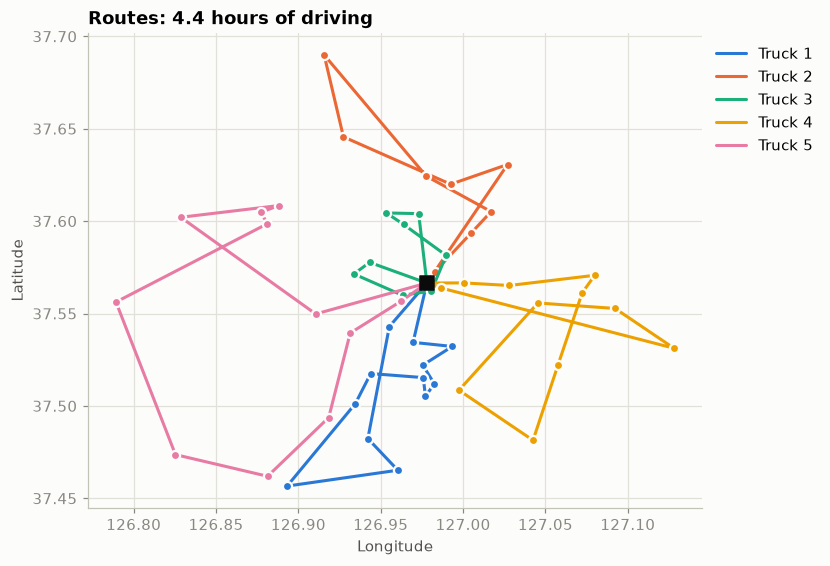

In [5]:
def route_points(plan, vehicle):
    """Latitude and longitude along one route, starting and ending at the depot."""
    stops = [plan.visits[i].location_index for i in vehicle.visit_indices]
    path = [vehicle.home_location_index, *stops, vehicle.home_location_index]
    return [plan.locations[i].longitude for i in path], [plan.locations[i].latitude for i in path]


def draw_routes(ax, plan):
    for k, vehicle in enumerate(plan.vehicles):
        if vehicle.visit_indices:
            xs, ys = route_points(plan, vehicle)
            ax.plot(xs, ys, color=COLORS[k], linewidth=2, solid_capstyle="round", label=vehicle.id)
            ax.scatter(xs[1:-1], ys[1:-1], s=36, color=COLORS[k], edgecolor="#fcfcfb", linewidth=1.5, zorder=2)
    for i in plan.unassigned_visit_indices:
        point = plan.locations[plan.visits[i].location_index]
        ax.scatter(point.longitude, point.latitude, marker="x", s=60, color="#0b0b0b", zorder=3)
    home = plan.locations[0]
    ax.scatter(home.longitude, home.latitude, marker="s", s=90, color="#0b0b0b", zorder=3)
    ax.set(xlabel="Longitude", ylabel="Latitude")
    ax.grid(True)


fig, ax = plt.subplots(figsize=(7.2, 5.6))
draw_routes(ax, plan)
ax.set_title(f"Routes: {-plan.score.soft / 3600:.1f} hours of driving")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### The same routes on a timeline

A map hides time. Here every truck is one row: driving, waiting for a window to open, and
service.

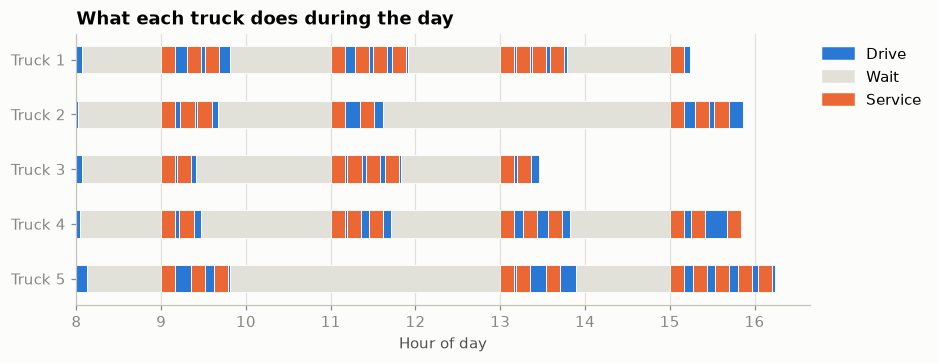

In [6]:
def segments(plan, vehicle):
    """(start, duration, kind) for one route, walking it the way the score does."""
    out, clock, here = [], vehicle.departure_time, vehicle.home_location_index
    for i in vehicle.visit_indices:
        visit = plan.visits[i]
        drive = plan.driving_time(here, visit.location_index)
        out.append((clock, drive, "drive"))
        clock += drive
        wait = max(0, visit.min_start_time - clock)
        if wait:
            out.append((clock, wait, "wait"))
            clock += wait
        out.append((clock, visit.service_duration, "service"))
        clock += visit.service_duration
        here = visit.location_index
    out.append((clock, plan.driving_time(here, vehicle.home_location_index), "drive"))
    return out


KIND_COLOR = {"drive": COLORS[0], "wait": "#e1e0d9", "service": COLORS[1]}
fig, ax = plt.subplots(figsize=(8.6, 3.2))
for row, vehicle in enumerate(plan.vehicles):
    for start, duration, kind in segments(plan, vehicle):
        ax.barh(row, duration / HOUR, left=start / HOUR, height=0.5, color=KIND_COLOR[kind],
                edgecolor="#fcfcfb", linewidth=0.6)
ax.set_yticks(range(len(plan.vehicles)), [v.id for v in plan.vehicles])
ax.invert_yaxis()
ax.set(title="What each truck does during the day", xlabel="Hour of day")
ax.grid(True, axis="x")
ax.legend(handles=[Patch(color=KIND_COLOR[k], label=k.capitalize()) for k in KIND_COLOR],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The solver stores each visit's arrival time on the object, so a plan can be verified from the
output alone. This recomputes the two hard rules with no solver code: the load on each truck, and
whether each service finishes inside its window.

every visit served exactly once: True
late visits: []


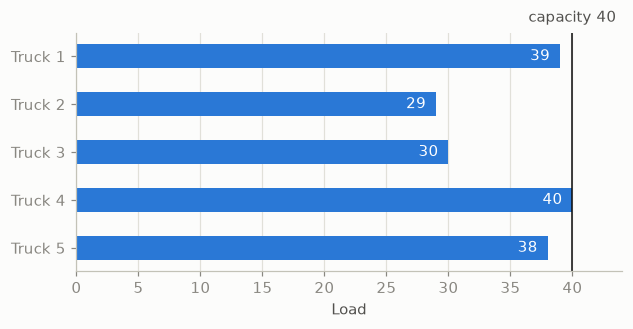

In [7]:
loads = [sum(plan.visits[i].demand for i in v.visit_indices) for v in plan.vehicles]
late = [
    v.id for v in plan.visits
    if v.vehicle_index >= 0 and max(v.arrival_time, v.min_start_time) + v.service_duration > v.max_end_time
]
served = sorted(i for vehicle in plan.vehicles for i in vehicle.visit_indices)

print("every visit served exactly once:", served == list(range(len(plan.visits))))
print("late visits:", late)

fig, ax = plt.subplots(figsize=(6.4, 2.8))
names = [v.id for v in plan.vehicles]
ax.barh(names, loads, height=0.5, color=COLORS[0])
ax.axvline(40, color="#0b0b0b", linewidth=1)
ax.text(40, -0.72, "capacity 40", ha="center", color=INK)
for row, load in enumerate(loads):
    ax.text(load - 0.8, row, str(load), va="center", ha="right", color="white")
ax.invert_yaxis()
ax.set(xlim=(0, 44), xlabel="Load")
ax.grid(True, axis="x")
plt.show()

## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and
`solve_with_constraints` takes the list you want. Only listed constraints are scored, so keep
`maximize_visits_assigned` unless skipping every customer should be free.

In [8]:
for name in vrp.list_constraints():
    print(name)

vehicle_capacity
service_finished_after_max_end_time
minimize_travel_time
max_travel_time
max_route_duration
vehicle_end_time
max_stops
max_route_radius
minimize_enclosing_circle_radius
min_capacity_utilization
minimize_route_duration
minimize_latency
vehicle_fixed_cost
maximize_visits_assigned


The default objective only minimizes total driving, so nothing keeps the work even: one driver can
get far more stops than another. Suppose no truck should make more than 11 stops. That takes two
steps: set the limit on the vehicles, and make sure `max_stops` is scored.

`weight` scales a constraint, `hard` moves it between levels, and `exponent=2` makes large
violations much costlier than small ones.

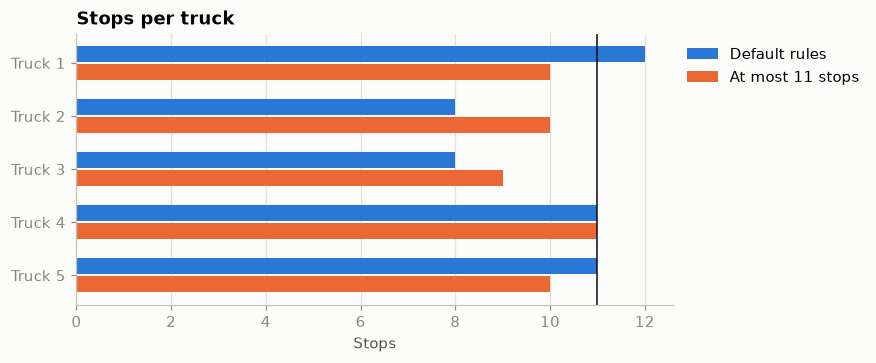

default : hard 0, 4.37 h driving
at most 11: hard 0, 4.31 h driving


In [9]:
STOP_LIMIT = 11

capped = make_plan()
for vehicle in capped.vehicles:
    vehicle.max_stops = STOP_LIMIT

vrp.Solver(config).solve_with_constraints(capped, rules.get_constraints([
    rules.vehicle_capacity,
    rules.service_finished_after_max_end_time,
    rules.maximize_visits_assigned,
    rules.minimize_travel_time,
    rules.MaxStops(weight=100, hard=True),
]))

y = np.arange(len(plan.vehicles))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(y - 0.17, [len(v.visit_indices) for v in plan.vehicles], height=0.3, color=COLORS[0], label="Default rules")
ax.barh(y + 0.17, [len(v.visit_indices) for v in capped.vehicles], height=0.3, color=COLORS[1], label="At most 11 stops")
ax.axvline(STOP_LIMIT, color="#0b0b0b", linewidth=1)
ax.set_yticks(y, [v.id for v in plan.vehicles])
ax.invert_yaxis()
ax.set(title="Stops per truck", xlabel="Stops")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"default : hard {plan.score.hard}, {-plan.score.soft / HOUR:.2f} h driving")
print(f"at most {STOP_LIMIT}: hard {capped.score.hard}, {-capped.score.soft / HOUR:.2f} h driving")

The solver runs for a fixed time, so these numbers are the best found in that time rather than proven
optima. A small difference between two runs can be search noise, even when one run has a tighter rule.

## 5. Too few trucks

When the fleet cannot serve everyone, the medium level decides who is left out: a visit off every
route costs its service minutes, and the solver keeps all the hard rules. Black crosses mark the
customers it gave up.

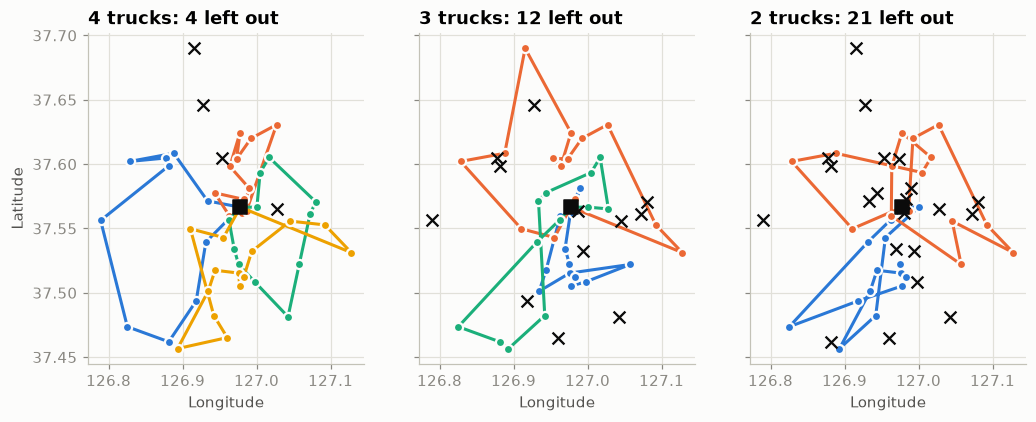

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharex=True, sharey=True)
for ax, count in zip(axes, [4, 3, 2]):
    small = make_plan(count)
    vrp.Solver(config).solve(small)
    draw_routes(ax, small)
    ax.set_title(f"{count} truck{'s' if count > 1 else ''}: {len(small.unassigned_visit_indices)} left out")
axes[1].set_ylabel("")
axes[2].set_ylabel("")
plt.show()

## 6. JSON input and warm starts

Services usually exchange JSON rather than engine objects. The pydantic models in
`optimaru.vehicle_routing.models` mirror the problem, and `solve_request` returns a
`RouteSolution` that also reports metrics per vehicle.

`with_initial_solution` turns a previous answer into the start of the next search. That is how you
keep working from yesterday's plan or spend a little more time on a result. The search below runs
in short rounds, each continuing from the last one.

Give each round its own `random_seed`. The same start with the same seed repeats the same search, so
with a fixed seed every round after the first one that finds nothing new returns the same answer.

feasible: True
Truck 1: 10 stops, load 39, 1.0 h driving, 3.6 h waiting
Truck 2: 10 stops, load 35, 0.9 h driving, 5.2 h waiting
Truck 3: 9 stops, load 27, 0.9 h driving, 5.9 h waiting
Truck 4: 10 stops, load 35, 1.0 h driving, 5.2 h waiting
Truck 5: 11 stops, load 40, 0.5 h driving, 4.9 h waiting


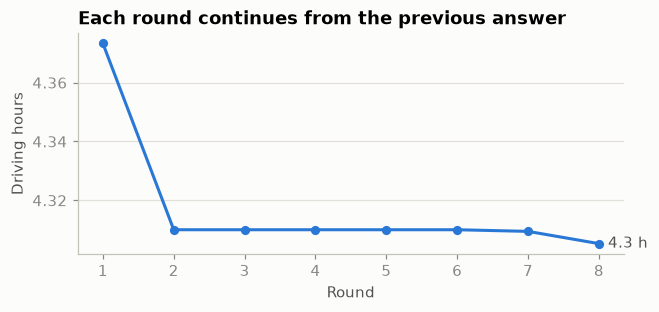

In [11]:
def to_request(timelimit):
    vehicles = [
        VehicleModel(id=f"Truck {k + 1}", capacity=40, depot=DEPOT, departure_time=8 * HOUR, return_to_depot=True)
        for k in range(5)
    ]
    stops = [
        VisitModel(
            id=v.id, name=v.name, demand=v.demand, service_duration=v.service_duration,
            location=(locations[v.location_index].latitude, locations[v.location_index].longitude),
            min_start_time=v.min_start_time, max_end_time=v.max_end_time,
        )
        for v in visits
    ]
    return RoutePlanRequest(timelimit=timelimit, random_seed=1, model_input=RoutingInput(vehicles=vehicles, visits=stops))


request = to_request(timelimit=0.02)
history = []
for round_number in range(8):
    request.random_seed = round_number
    solution = solve_request(request)
    history.append(solution.total_driving_seconds / HOUR)
    request = with_initial_solution(request, solution)

print("feasible:", solution.feasible)
for vehicle_id, metrics in solution.vehicle_metrics.items():
    print(f"{vehicle_id}: {metrics.stops} stops, load {metrics.load}, "
          f"{metrics.driving_seconds / 3600:.1f} h driving, {metrics.waiting_seconds / 3600:.1f} h waiting")

fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.plot(range(1, len(history) + 1), history, color=COLORS[0], linewidth=2, marker="o", markersize=5)
ax.annotate(f"{history[-1]:.1f} h", (len(history), history[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", color=INK)
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Driving hours")
ax.grid(True, axis="y")
plt.show()

## Next steps

- The vehicle options above are the common ones. `Vehicle` also takes `max_travel_time`, `max_stops`,
  `max_end_time`, `min_load_ratio`, `fixed_cost` and `max_route_radius_meters`.
- `use-cases/vehicle-routing/README.md` covers the basic solver options and how to add your own
  moves and constraints in C++.
- For orders that must be picked up before they are dropped off, see `pickup-delivery.ipynb`.